In [1]:
suppressMessages(library(DESeq2))
suppressMessages(library(ggplot2))
suppressMessages(library(cowplot))
suppressMessages(library(dplyr))
suppressMessages(library(apeglm))
suppressMessages(library(ggrepel))

Warning message:
“package ‘ggplot2’ was built under R version 4.5.3”
Warning message:
“package ‘dplyr’ was built under R version 4.5.3”
Warning message:
“package ‘ggrepel’ was built under R version 4.5.3”


In [2]:
in_dir <- "../../results/09_analysis_podocyte_niche/09_create_bulk"
out_dir <- "../../results/09_analysis_podocyte_niche/11_de_analysis_Tubulointerstitial"

# create output directory if it doesn't exist
if (!dir.exists(out_dir)) {
   dir.create(out_dir, recursive = TRUE)
}

In [3]:
df_counts <- t(read.csv(glue::glue("{in_dir}/Tubulointerstitial_counts_bulk.csv"), row.names = 1, check.names = FALSE))
df_meta <- read.csv(glue::glue("{in_dir}/Tubulointerstitial_meta_bulk.csv"), row.names = 1, check.names = FALSE)

In [4]:
head(df_counts)

,sample_15837,sample_15852,sample_16512,sample_21022,sample_8262,sample_B23-03794-5,sample_B23-05785-7-1,sample_B23-05785-7-2,sample_X1842,sample_X1845,sample_X1899,sample_X1912
SAMD11,98,185,118,462,14,433,781,1064,610,216,868,659
NOC2L,172,202,295,508,49,564,1088,1178,1546,455,1352,2111
KLHL17,67,96,95,173,26,291,608,426,670,182,528,881
PLEKHN1,49,71,46,127,22,82,293,204,281,66,256,518
PERM1,12,40,19,26,9,104,278,174,105,21,90,79
HES4,228,257,279,579,125,902,1894,1670,1392,282,1112,1178


In [5]:
head(df_meta)

,group,annotation_v2
,<chr>,<chr>
sample_15837,SRC,Tubulointerstitial
sample_15852,SRC,Tubulointerstitial
sample_16512,SRC,Tubulointerstitial
sample_21022,SRC,Tubulointerstitial
sample_8262,SRC,Tubulointerstitial
sample_B23-03794-5,Normal,Tubulointerstitial


In [6]:
dds <- DESeqDataSetFromMatrix(countData = df_counts,
                              colData = df_meta,
                              design = ~ group)

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”


In [7]:
keep <- rowSums(counts(dds) >= 10) >= 5
dds <- dds[keep,]

In [8]:
dds

class: DESeqDataSet 
dim: 17992 12 
metadata(1): version
assays(1): counts
rownames(17992): SAMD11 NOC2L ... KDM5D EIF1AY
rowData names(0):
colnames(12): sample_15837 sample_15852 ... sample_X1899 sample_X1912
colData names(2): group annotation_v2

In [9]:
dds <- DESeq(dds)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [10]:
df_res1 <- results(dds, contrast = c("group", "SRC", "Normal")) %>%
    as.data.frame() %>%
    tidyr::drop_na()

df_res2 <- results(dds, contrast = c("group", "LN", "Normal")) %>%
    as.data.frame() %>%
    tidyr::drop_na()

write.csv(df_res1, glue::glue("{out_dir}/de_results_SRC_vs_Normal.csv"))
write.csv(df_res2, glue::glue("{out_dir}/de_results_LN_vs_Normal.csv"))

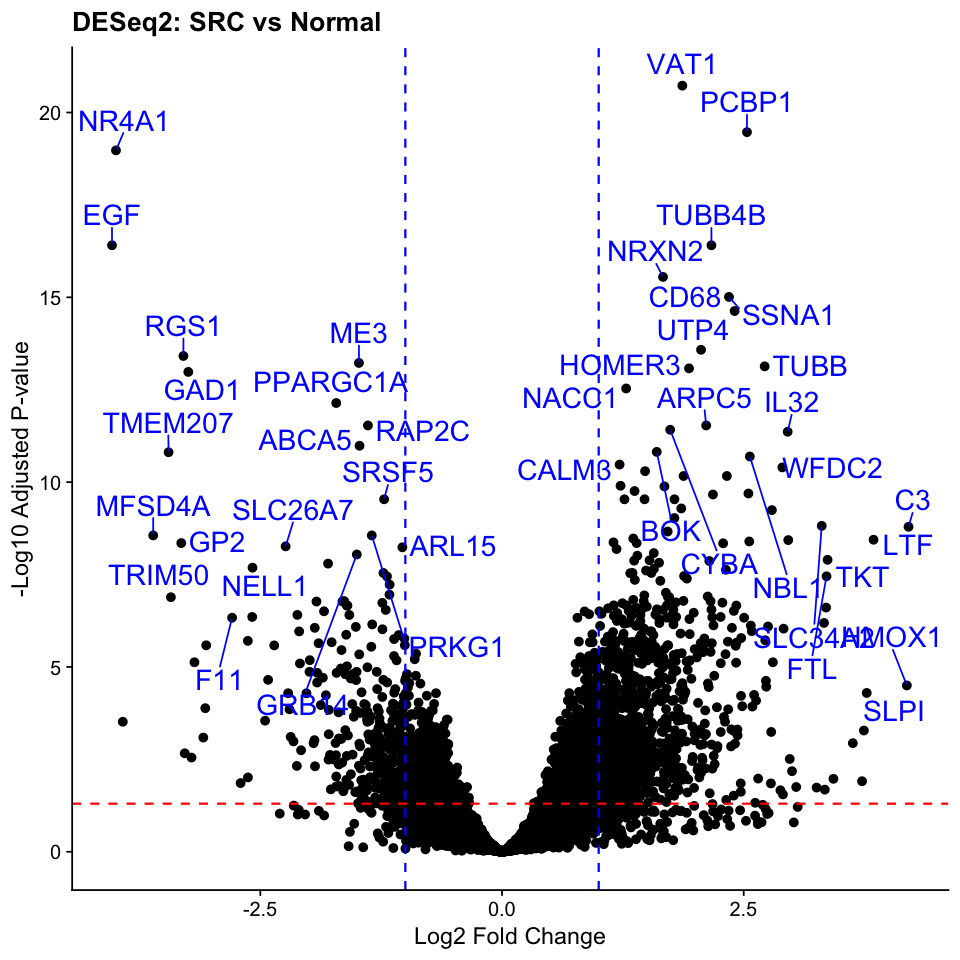

In [11]:
options(repr.plot.width = 8, repr.plot.height = 8)

df_text <- subset(df_res1, padj < 0.0001 & abs(log2FoldChange) > 1)

p <- ggplot(data = df_res1, aes(x = log2FoldChange, y = -log10(padj))) +
    geom_point() +
    geom_text_repel(data = df_text, aes(label = rownames(df_text)), vjust = -1, size = 6, color = "blue") +
    ggtitle("DESeq2: SRC vs Normal") +
    xlab("Log2 Fold Change") +
    ylab("-Log10 Adjusted P-value") +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "red") +
    geom_vline(xintercept = c(-1, 1), linetype = "dashed", color = "blue") +
    theme_cowplot()

print(p)

ggsave(plot = p, 
filename = glue::glue("{out_dir}/volcano_plot_SRC_vs_Normal.png"), 
width = 8, height = 8)

ggsave(plot = p, 
filename = glue::glue("{out_dir}/volcano_plot_SRC_vs_Normal.pdf"), 
width = 8, height = 8)

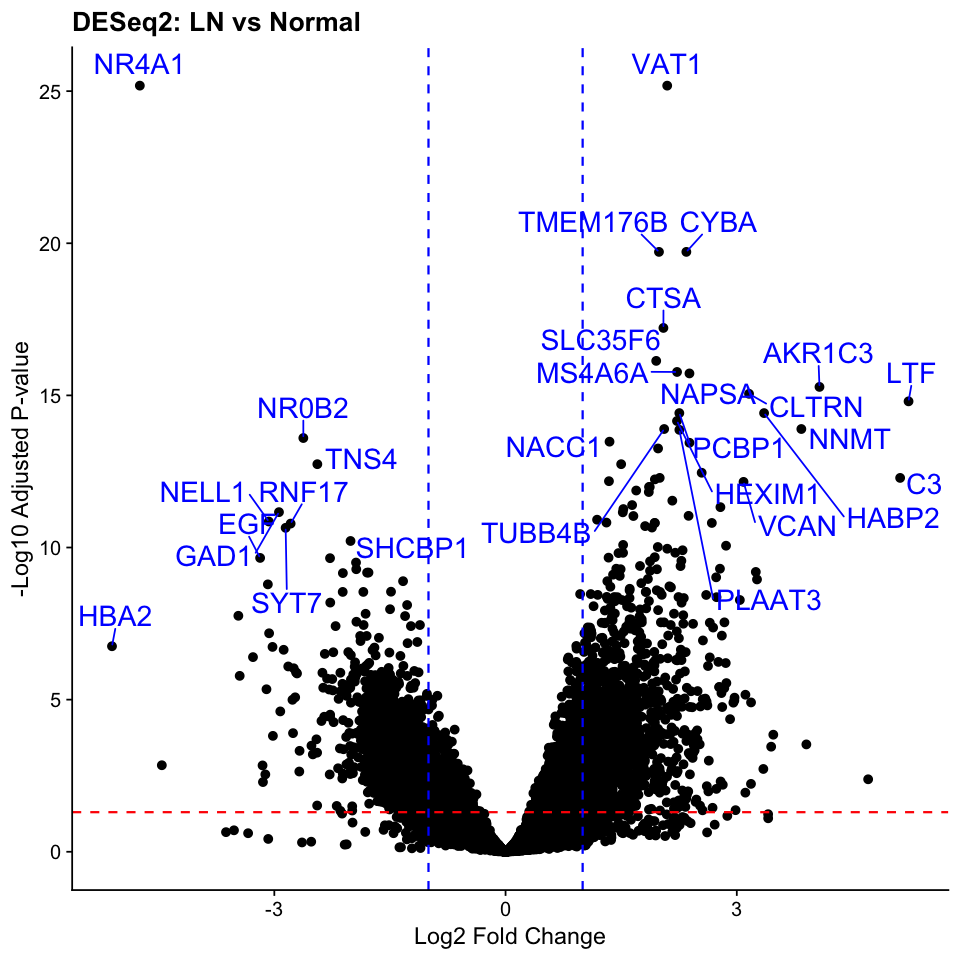

In [12]:
options(repr.plot.width = 8, repr.plot.height = 8)

df_text <- subset(df_res2, padj < 0.0001 & abs(log2FoldChange) > 1)

p <- ggplot(data = df_res2, aes(x = log2FoldChange, y = -log10(padj))) +
    geom_point() +
    geom_text_repel(data = df_text, aes(label = rownames(df_text)), vjust = -1, size = 6, color = "blue") +
    ggtitle("DESeq2: LN vs Normal") +
    xlab("Log2 Fold Change") +
    ylab("-Log10 Adjusted P-value") +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "red") +
    geom_vline(xintercept = c(-1, 1), linetype = "dashed", color = "blue") +
    theme_cowplot()

print(p)

ggsave(plot = p, 
filename = glue::glue("{out_dir}/volcano_plot_LN_vs_Normal.png"), 
width = 8, height = 8)

ggsave(plot = p, 
filename = glue::glue("{out_dir}/volcano_plot_LN_vs_Normal.pdf"), 
width = 8, height = 8)

In [13]:
options(repr.plot.width = 4, repr.plot.height = 4)

vsd <- vst(dds, blind = FALSE)  # or use rlog(dds)

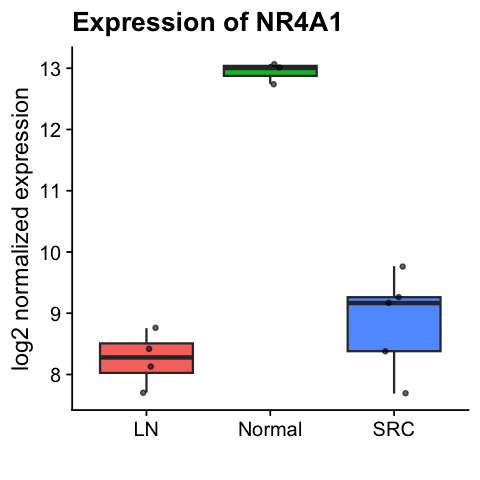

In [14]:
plot_df <- data.frame(
  expression = assay(vsd)["NR4A1", ],
  group = colData(dds)$group
)

ggplot(plot_df, aes(x = group, y = expression, fill = group)) +
  geom_boxplot() +
  geom_jitter(width = 0.1, size = 1, alpha = 0.6) +
  xlab("") +
  labs(title = paste("Expression of", "NR4A1"), y = "log2 normalized expression") +
  theme_cowplot() +
    theme(legend.position = "none")

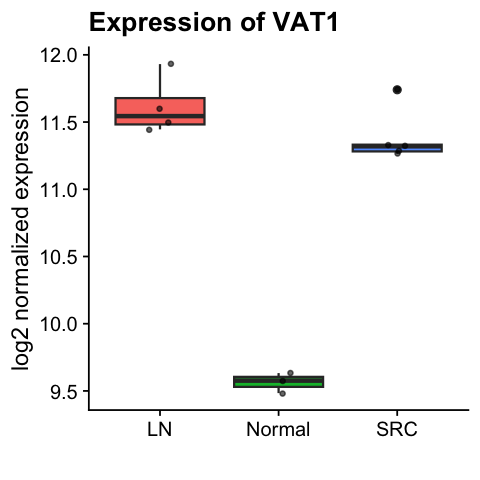

In [15]:
plot_df <- data.frame(
  expression = assay(vsd)["VAT1", ],
  group = colData(dds)$group
)

ggplot(plot_df, aes(x = group, y = expression, fill = group)) +
  geom_boxplot() +
  geom_jitter(width = 0.1, size = 1, alpha = 0.6) +
  xlab("") +
  labs(title = paste("Expression of", "VAT1"), y = "log2 normalized expression") +
  theme_cowplot() +
    theme(legend.position = "none")